In [18]:
import random
import math

random.seed(425)

print("Libraries imported successfully!")

Libraries imported successfully!


In [19]:
def sample_uniform(a, b):
    u = random.random()
    return a + (b - a) * u

print(sample_uniform(0, 10))

4.1901579565953115


In [20]:
def sample_normal(mu, sigma):
    u1 = 1 - random.random()
    u2 = random.random()

    z = math.sqrt(-2 * math.log(u1)) * math.cos(2 * math.pi * u2)

    return mu + sigma * z

print(sample_normal(3, 1))

3.5737412133099475


In [21]:
def sample_poisson(lam):
    L = math.exp(-lam)
    k = 0
    p = 1

    while True:
        p = p * random.random()

        if p <= L:
            return k

        k = k + 1

print(sample_poisson(2))


4


In [22]:
def calculate_mean(data):
    return sum(data) / len(data)

def calculate_variance(data):
    mean = calculate_mean(data)
    return sum((x - mean) ** 2 for x in data) / len(data)


random.seed(425)

uniform_samples = [sample_uniform(0, 10) for _ in range(100000)]
normal_samples = [sample_normal(3, 1) for _ in range(100000)]
poisson_samples = [sample_poisson(2) for _ in range(100000)]

print("Uniform Mean:", calculate_mean(uniform_samples))
print("Uniform Variance:", calculate_variance(uniform_samples))

print("\nNormal Mean:", calculate_mean(normal_samples))
print("Normal Variance:", calculate_variance(normal_samples))

print("\nPoisson Mean:", calculate_mean(poisson_samples))
print("Poisson Variance:", calculate_variance(poisson_samples))



Uniform Mean: 4.9879233169492325
Uniform Variance: 8.309715440419808

Normal Mean: 2.996357089167957
Normal Variance: 1.002903621414598

Poisson Mean: 1.999
Poisson Variance: 2.0006589999999997


In [23]:
def generate_ratings(n, dist, **params):
    ratings = []

    for _ in range(n):
        if dist == "uniform":
            x = sample_uniform(0.5, 5.5)

        elif dist == "normal":
            x = sample_normal(
                params.get("mu", 3),
                params.get("sigma", 1)
            )

        elif dist == "poisson":
            x = 1 + sample_poisson(params.get("lam", 2))

        else:
            raise ValueError("Unknown distribution")

        rating = round(x)
        rating = max(1, min(5, rating))

        ratings.append(rating)

    return ratings


print(generate_ratings(10, "uniform"))
print(generate_ratings(10, "normal"))
print(generate_ratings(10, "poisson"))


[1, 2, 3, 5, 1, 2, 4, 3, 3, 3]
[4, 2, 2, 4, 1, 4, 3, 3, 4, 3]
[4, 3, 4, 2, 3, 3, 5, 3, 3, 2]


In [24]:
def assign_ratings(n_items, dist, max_fill=0.5, **params):
    row = [None] * n_items

    max_ratings = int(max_fill * n_items)
    k = random.randint(5, max_ratings)

    selected_items = random.sample(range(n_items), k)
    ratings = generate_ratings(k, dist, **params)

    for item_id, rating in zip(selected_items, ratings):
        row[item_id] = rating

    assert row.count(None) >= n_items * 0.5

    return row


test_row = assign_ratings(100, "uniform")

print("Total items:", len(test_row))
print("Rated items:", sum(r is not None for r in test_row))
print("Missing ratings:", test_row.count(None))


Total items: 100
Rated items: 18
Missing ratings: 82


In [25]:
random.seed(425)

n_users = 5000
n_items = 100

uniform_matrix = [
    assign_ratings(n_items, "uniform")
    for _ in range(n_users)
]

normal_matrix = [
    assign_ratings(n_items, "normal")
    for _ in range(n_users)
]

poisson_matrix = [
    assign_ratings(n_items, "poisson")
    for _ in range(n_users)
]

print("Uniform matrix:", len(uniform_matrix), "users")
print("Normal matrix:", len(normal_matrix), "users")
print("Poisson matrix:", len(poisson_matrix), "users")


Uniform matrix: 5000 users
Normal matrix: 5000 users
Poisson matrix: 5000 users


In [26]:
matrices = {
    "Uniform": uniform_matrix,
    "Normal": normal_matrix,
    "Poisson": poisson_matrix
}

for name, matrix in matrices.items():
    total_cells = len(matrix) * len(matrix[0])

    missing_cells = sum(
        rating is None
        for row in matrix
        for rating in row
    )

    sparsity = missing_cells / total_cells

    print(f"\n{name}")
    print("Total cells:", total_cells)
    print("Missing ratings:", missing_cells)
    print("Sparsity:", round(sparsity, 4))



Uniform
Total cells: 500000
Missing ratings: 364297
Sparsity: 0.7286

Normal
Total cells: 500000
Missing ratings: 362635
Sparsity: 0.7253

Poisson
Total cells: 500000
Missing ratings: 361852
Sparsity: 0.7237


In [27]:
import csv

def save_matrix(matrix, filename):
    with open(filename, "w", newline="") as file:
        writer = csv.writer(file)

        writer.writerow(["user_id", "item_id", "rating"])

        for user_id, row in enumerate(matrix):
            for item_id, rating in enumerate(row):
                if rating is not None:
                    writer.writerow([user_id, item_id, rating])


save_matrix(uniform_matrix, "uniform.csv")
save_matrix(normal_matrix, "normal.csv")
save_matrix(poisson_matrix, "poisson.csv")

print("All CSV files saved successfully!")


All CSV files saved successfully!


In [28]:
def analyze_matrix(matrix):
    all_ratings = []
    user_means = []
    item_ratings = [[] for _ in range(len(matrix[0]))]

    for row in matrix:
        ratings = [r for r in row if r is not None]

        if ratings:
            user_means.append(sum(ratings) / len(ratings))

        for item_id, rating in enumerate(row):
            if rating is not None:
                all_ratings.append(rating)
                item_ratings[item_id].append(rating)

    global_mean = sum(all_ratings) / len(all_ratings)

    mean_of_user_means = sum(user_means) / len(user_means)

    item_means = [
        sum(ratings) / len(ratings)
        for ratings in item_ratings
        if ratings
    ]

    total_cells = len(matrix) * len(matrix[0])
    missing = total_cells - len(all_ratings)

    return {
        "sparsity": missing / total_cells,
        "global_mean": global_mean,
        "mean_of_user_means": mean_of_user_means,
        "min_user_mean": min(user_means),
        "max_user_mean": max(user_means),
        "user_means": user_means,
        "item_means": item_means,
        "ratings": all_ratings
    }


results = {}

for name, matrix in matrices.items():
    results[name] = analyze_matrix(matrix)

    result = results[name]

    print(f"\n--- {name} ---")
    print(f"Sparsity: {result['sparsity']:.4f}")
    print(f"Global Mean: {result['global_mean']:.4f}")
    print(f"Mean of User Means: {result['mean_of_user_means']:.4f}")
    print(f"Minimum User Mean: {result['min_user_mean']:.4f}")
    print(f"Maximum User Mean: {result['max_user_mean']:.4f}")


--- Uniform ---
Sparsity: 0.7286
Global Mean: 3.0038
Mean of User Means: 3.0040
Minimum User Mean: 1.6667
Maximum User Mean: 4.3333

--- Normal ---
Sparsity: 0.7253
Global Mean: 2.9987
Mean of User Means: 2.9995
Minimum User Mean: 1.6000
Maximum User Mean: 4.6000

--- Poisson ---
Sparsity: 0.7237
Global Mean: 2.9229
Mean of User Means: 2.9206
Minimum User Mean: 1.4000
Maximum User Mean: 4.4000


In [29]:
def calculate_std(values):
    mean = sum(values) / len(values)

    variance = sum(
        (x - mean) ** 2 for x in values
    ) / len(values)

    return math.sqrt(variance)


def homogeneity_metrics(matrix):
    result = analyze_matrix(matrix)
    ratings = result["ratings"]

    n = len(ratings)

    counts = [
        ratings.count(v)
        for v in range(1, 6)
    ]

    probabilities = [
        count / n
        for count in counts
    ]

    entropy = 0

    for p in probabilities:
        if p > 0:
            entropy -= p * math.log(p)

    normalized_entropy = entropy / math.log(5)

    expected = n / 5

    chi_square = sum(
        (count - expected) ** 2 / expected
        for count in counts
    )

    user_std = calculate_std(result["user_means"])
    item_std = calculate_std(result["item_means"])

    popularity = [
        sum(row[i] is not None for row in matrix)
        for i in range(len(matrix[0]))
    ]

    sorted_popularity = sorted(popularity)

    total_popularity = sum(sorted_popularity)
    m = len(sorted_popularity)

    if total_popularity == 0:
        gini = 0
    else:
        weighted_sum = sum(
            (i + 1) * value
            for i, value in enumerate(sorted_popularity)
        )

        gini = (
            2 * weighted_sum / (m * total_popularity)
            - (m + 1) / m
        )

    return {
        "normalized_entropy": normalized_entropy,
        "chi_square": chi_square,
        "user_std": user_std,
        "item_std": item_std,
        "gini": gini
    }


for name, matrix in matrices.items():
    metrics = homogeneity_metrics(matrix)

    print(f"\n--- {name} ---")

    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")



--- Uniform ---
normalized_entropy: 1.0000
chi_square: 7.4796
user_std: 0.3206
item_std: 0.0321
gini: 0.0109

--- Normal ---
normalized_entropy: 0.8783
chi_square: 50286.4221
user_std: 0.2303
item_std: 0.0236
gini: 0.0133

--- Poisson ---
normalized_entropy: 0.9722
chi_square: 12406.1062
user_std: 0.2828
item_std: 0.0353
gini: 0.0120


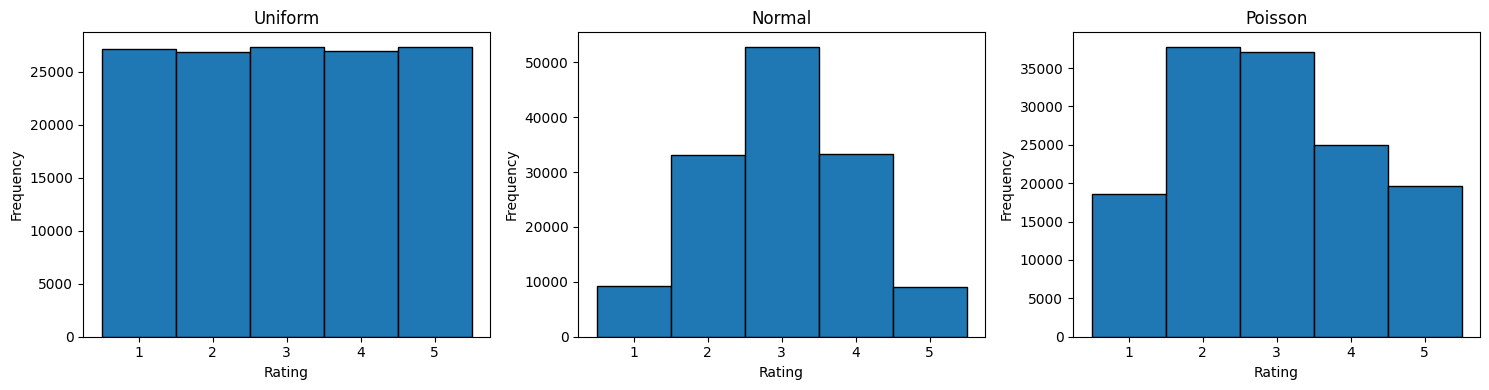

In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, result) in zip(axes, results.items()):
    ax.hist(
        result["ratings"],
        bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
        edgecolor="black"
    )

    ax.set_title(name)
    ax.set_xlabel("Rating")
    ax.set_ylabel("Frequency")
    ax.set_xticks([1, 2, 3, 4, 5])

plt.tight_layout()
plt.show()


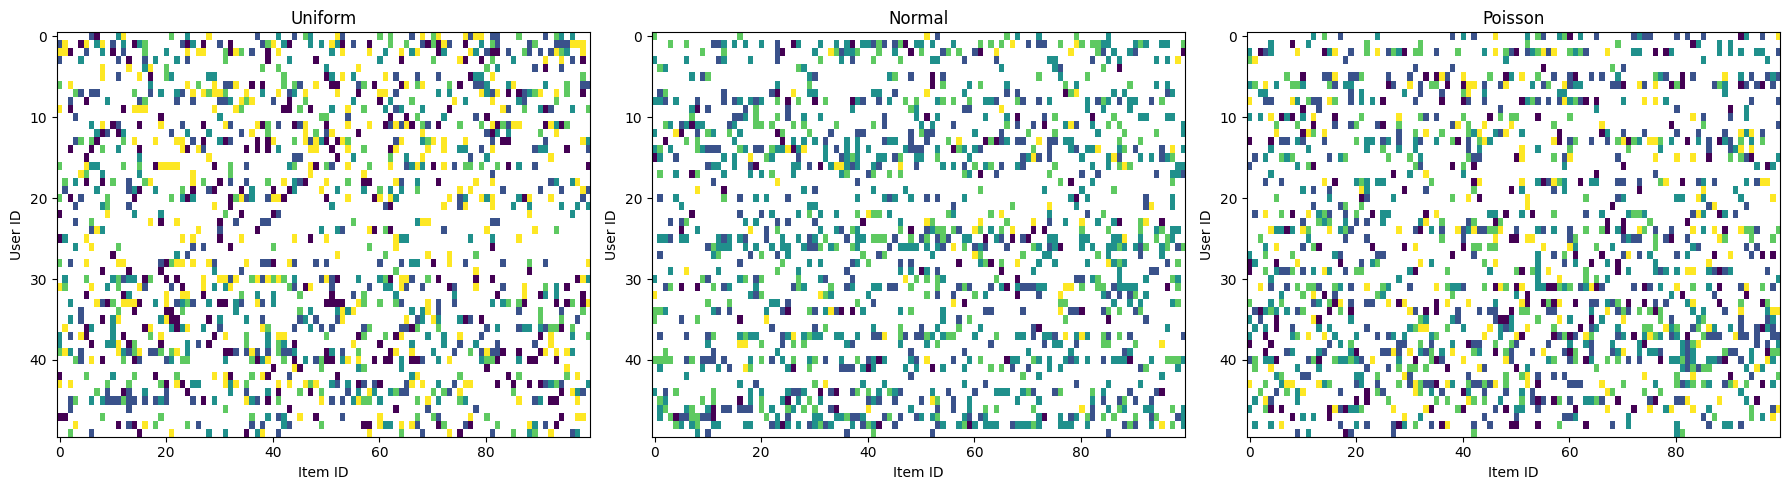

In [31]:
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, matrix) in zip(axes, matrices.items()):
    data = np.array([
        [
            np.nan if value is None else value
            for value in row
        ]
        for row in matrix[:50]
    ], dtype=float)

    masked_data = np.ma.masked_invalid(data)

    cmap = plt.cm.viridis.copy()
    cmap.set_bad("white")

    ax.imshow(
        masked_data,
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=1,
        vmax=5
    )

    ax.set_title(name)
    ax.set_xlabel("Item ID")
    ax.set_ylabel("User ID")

plt.tight_layout()
plt.show()



In [32]:
def complete_matrix(n_users, n_items, dist):
    matrix = []

    for _ in range(n_users):
        ratings = generate_ratings(n_items, dist)
        matrix.append(ratings)

    return matrix


random.seed(425)

full_matrix = complete_matrix(5000, 100, "normal")

all_ratings = [
    rating
    for row in full_matrix
    for rating in row
]

user_means = [
    sum(row) / len(row)
    for row in full_matrix
]

reference_global_mean = sum(all_ratings) / len(all_ratings)

reference_user_mean = sum(user_means) / len(user_means)

print("Matrix dimensions:", len(full_matrix), "x", len(full_matrix[0]))
print("Reference global mean:", round(reference_global_mean, 4))
print("Reference mean of user means:", round(reference_user_mean, 4))


Matrix dimensions: 5000 x 100
Reference global mean: 2.9975
Reference mean of user means: 2.9975


In [33]:
def hide_ratings(full, p, mechanism):
    n_users = len(full)
    n_items = len(full[0])

    hidden_matrix = [row.copy() for row in full]

    total = n_users * n_items
    keep_count = int((1 - p) * total)

    keys = []

    for u in range(n_users):
        for i in range(n_items):
            if mechanism == "random":
                key = random.random()

            elif mechanism == "dislike":
                rating = full[u][i]
                weight = rating
                key = random.random() / weight

            else:
                raise ValueError("Unknown mechanism")

            keys.append((key, u, i))

    keys.sort(reverse=True)

    for _, u, i in keys[keep_count:]:
        hidden_matrix[u][i] = None

    return hidden_matrix


random.seed(425)

test_hidden = hide_ratings(full_matrix, 0.5, "random")

remaining = sum(
    rating is not None
    for row in test_hidden
    for rating in row
)

missing = sum(
    rating is None
    for row in test_hidden
    for rating in row
)

print("Total ratings:", len(full_matrix) * len(full_matrix[0]))
print("Remaining ratings:", remaining)
print("Hidden ratings:", missing)
print("Actual hiding percentage:", missing / (len(full_matrix) * len(full_matrix[0])))


Total ratings: 500000
Remaining ratings: 250000
Hidden ratings: 250000
Actual hiding percentage: 0.5


In [34]:
def calculate_means(matrix):
    ratings = [
        rating
        for row in matrix
        for rating in row
        if rating is not None
    ]

    user_means = []

    for row in matrix:
        user_ratings = [r for r in row if r is not None]

        if user_ratings:
            user_means.append(sum(user_ratings) / len(user_ratings))

    global_mean = sum(ratings) / len(ratings)
    mean_of_user_means = sum(user_means) / len(user_means)

    return global_mean, mean_of_user_means

In [35]:
global_mean, user_mean = calculate_means(test_hidden)

print("Global mean after hiding:", round(global_mean, 4))
print("Mean of user means after hiding:", round(user_mean, 4))
print("Reference global mean:", round(reference_global_mean, 4))
print("Reference mean of user means:", round(reference_user_mean, 4))

Global mean after hiding: 2.9968
Mean of user means after hiding: 2.9969
Reference global mean: 2.9975
Reference mean of user means: 2.9975


In [36]:
global_mean, user_mean = calculate_means(test_hidden)

global_bias = global_mean - reference_global_mean
user_bias = user_mean - reference_user_mean

print("Global Mean Bias:", round(global_bias, 6))
print("Mean of User Means Bias:", round(user_bias, 6))

Global Mean Bias: -0.000716
Mean of User Means Bias: -0.000617


In [37]:
def run_experiments(full_matrix, proportions, mechanisms, trials=20):
    results = []

    for p in proportions:
        for mechanism in mechanisms:
            global_biases = []
            user_biases = []

            for trial in range(trials):
                hidden = hide_ratings(full_matrix, p, mechanism)

                global_mean, user_mean = calculate_means(hidden)

                global_biases.append(
                    global_mean - reference_global_mean
                )

                user_biases.append(
                    user_mean - reference_user_mean
                )

            avg_global_bias = sum(global_biases) / trials
            avg_user_bias = sum(user_biases) / trials

            global_error = math.sqrt(
                sum(b ** 2 for b in global_biases) / trials
            )

            user_error = math.sqrt(
                sum(b ** 2 for b in user_biases) / trials
            )

            results.append({
                "Hiding %": p * 100,
                "Mechanism": mechanism,
                "Global Bias": avg_global_bias,
                "User Mean Bias": avg_user_bias,
                "Global Random Error": global_error,
                "User Mean Random Error": user_error
            })

    return results

In [38]:
random.seed(425)

results = run_experiments(
    full_matrix,
    proportions=[0.5, 0.75, 0.9],
    mechanisms=["random", "dislike"],
    trials=20
)

for result in results:
    print(result)
    print("-" * 50)

{'Hiding %': 50.0, 'Mechanism': 'random', 'Global Bias': 0.0006955999999999519, 'User Mean Bias': 0.0006119068205607148, 'Global Random Error': 0.0016102745107589094, 'User Mean Random Error': 0.0015429168940277165}
--------------------------------------------------
{'Hiding %': 50.0, 'Mechanism': 'dislike', 'Global Bias': -0.3397174000000001, 'User Mean Bias': -0.3397897419649246, 'Global Random Error': 0.3397191821643283, 'User Mean Random Error': 0.3397916078385366}
--------------------------------------------------
{'Hiding %': 75.0, 'Mechanism': 'random', 'Global Bias': -0.00024120000000009688, 'User Mean Bias': -0.00012052907956281445, 'Global Random Error': 0.002276009841806451, 'User Mean Random Error': 0.0022987984133466385}
--------------------------------------------------
{'Hiding %': 75.0, 'Mechanism': 'dislike', 'Global Bias': -0.8590232, 'User Mean Bias': -0.8590416073652891, 'Global Random Error': 0.859024464111704, 'User Mean Random Error': 0.8590429570265952}
--------

In [44]:
def hide_ratings(full, p, mechanism):
    n_users = len(full)
    n_items = len(full[0])
    hidden_matrix = [row.copy() for row in full]

    total = n_users * n_items
    keep_count = int((1 - p) * total)
    keys = []

    for u in range(n_users):
        for i in range(n_items):
            if mechanism == "random":
                key = random.random()
            elif mechanism == "dislike":
                rating = full[u][i]
                key = random.random() * rating
            else:
                raise ValueError("Unknown mechanism")

            keys.append((key, u, i))

    keys.sort(reverse=True)

    for _, u, i in keys[keep_count:]:
        hidden_matrix[u][i] = None

    return hidden_matrix

In [45]:
random.seed(425)

test = hide_ratings(full_matrix, 0.5, "dislike")

print("Matrix size:", len(test), "x", len(test[0]))

remaining = sum(
    rating is not None
    for row in test
    for rating in row
)

print("Remaining ratings:", remaining)
print("Hidden ratings:", 500000 - remaining)

Matrix size: 5000 x 100
Remaining ratings: 250000
Hidden ratings: 250000


In [46]:
random.seed(425)

results = run_experiments(
    full_matrix,
    proportions=[0.5, 0.75, 0.9],
    mechanisms=["random", "dislike"],
    trials=20
)

for result in results:
    print(result)
    print("-" * 50)

{'Hiding %': 50.0, 'Mechanism': 'random', 'Global Bias': 0.0006955999999999519, 'User Mean Bias': 0.0006119068205607148, 'Global Random Error': 0.0016102745107589094, 'User Mean Random Error': 0.0015429168940277165}
--------------------------------------------------
{'Hiding %': 50.0, 'Mechanism': 'dislike', 'Global Bias': 0.357719, 'User Mean Bias': 0.3577904600977736, 'Global Random Error': 0.3577205034693986, 'User Mean Random Error': 0.35779209869814976}
--------------------------------------------------
{'Hiding %': 75.0, 'Mechanism': 'random', 'Global Bias': -0.00024120000000009688, 'User Mean Bias': -0.00012052907956281445, 'Global Random Error': 0.002276009841806451, 'User Mean Random Error': 0.0022987984133466385}
--------------------------------------------------
{'Hiding %': 75.0, 'Mechanism': 'dislike', 'Global Bias': 0.7373379999999999, 'User Mean Bias': 0.7376109268983339, 'Global Random Error': 0.7373395029092094, 'User Mean Random Error': 0.7376128173370167}
-----------

In [47]:
def add_new_items(matrix, n_new_items=10):
    updated_matrix = [row.copy() for row in matrix]

    for row in updated_matrix:
        row.extend([None] * n_new_items)

    n_users = len(updated_matrix)

    for item_index in range(n_new_items):
        n_ratings = int(random.random() * 3)

        if n_ratings > 0:
            selected_users = random.sample(
                range(n_users), n_ratings
            )

            for user in selected_users:
                updated_matrix[user][len(matrix[0]) + item_index] = (
                    generate_ratings(1, "normal")[0]
                )

    return updated_matrix

In [50]:
%whos

Variable                Type              Data/Info
---------------------------------------------------
add_new_items           function          <function add_new_items at 0x7ed98d19d6c0>
all_ratings             list              n=500000
analyze_matrix          function          <function analyze_matrix at 0x7ed98ee26980>
assign_ratings          function          <function assign_ratings at 0x7ed98ee26a20>
ax                      Axes              Axes(0.695502,0.116556;0.296165x0.808778)
axes                    ndarray           3: 3 elems, type `object`, 24 bytes
calculate_mean          function          <function calculate_mean at 0x7ed98ee26020>
calculate_means         function          <function calculate_means at 0x7ed9ad1d7a60>
calculate_std           function          <function calculate_std at 0x7ed98ee25f80>
calculate_variance      function          <function calculate_variance at 0x7ed98ee25c60>
cmap                    ListedColormap    <matplotlib.colors.Listed<...>object

In [51]:
random.seed(425)

matrix_with_new_items = add_new_items(full_matrix, 10)

print("Users:", len(matrix_with_new_items))
print("Items:", len(matrix_with_new_items[0]))

Users: 5000
Items: 110


In [52]:
def add_new_users(matrix, n_new_users=500):
    updated_matrix = [row.copy() for row in matrix]

    old_items = len(matrix[0]) - 10

    for _ in range(n_new_users):
        new_user = [None] * len(matrix[0])

        k = 1 + int(random.random() * 3)

        selected_items = random.sample(range(old_items), k)

        ratings = generate_ratings(k, "normal")

        for item, rating in zip(selected_items, ratings):
            new_user[item] = rating

        updated_matrix.append(new_user)

    return updated_matrix

In [53]:
random.seed(425)

final_matrix = add_new_users(matrix_with_new_items, 500)

print("Users:", len(final_matrix))
print("Items:", len(final_matrix[0]))

Users: 5500
Items: 110


In [54]:
total_cells = len(final_matrix) * len(final_matrix[0])

missing_cells = sum(
    rating is None
    for row in final_matrix
    for rating in row
)

sparsity = missing_cells / total_cells

cold_users = sum(
    all(rating is None for rating in row)
    for row in final_matrix
)

cold_items = sum(
    all(row[j] is None for row in final_matrix)
    for j in range(len(final_matrix[0]))
)

print("Total Users:", len(final_matrix))
print("Total Items:", len(final_matrix[0]))
print("Sparsity:", round(sparsity * 100, 2), "%")
print("Cold Users:", cold_users)
print("Cold Items:", cold_items)

Total Users: 5500
Total Items: 110
Sparsity: 17.19 %
Cold Users: 0
Cold Items: 3


In [55]:
new_users = final_matrix[-500:]

overlap_count = 0
no_overlap_count = 0

for i in range(len(new_users)):
    for j in range(i + 1, len(new_users)):
        items_i = {
            k for k, rating in enumerate(new_users[i][:100])
            if rating is not None
        }

        items_j = {
            k for k, rating in enumerate(new_users[j][:100])
            if rating is not None
        }

        if items_i.intersection(items_j):
            overlap_count += 1
        else:
            no_overlap_count += 1

print("User pairs with co-rated items:", overlap_count)
print("User pairs with no overlap:", no_overlap_count)
print("Total pairs:", overlap_count + no_overlap_count)

User pairs with co-rated items: 4929
User pairs with no overlap: 119821
Total pairs: 124750


In [56]:
print("Uniform matrix dimensions:",
      len(uniform_matrix), "x", len(uniform_matrix[0]))

print("Normal matrix dimensions:",
      len(normal_matrix), "x", len(normal_matrix[0]))

print("Poisson matrix dimensions:",
      len(poisson_matrix), "x", len(poisson_matrix[0]))

Uniform matrix dimensions: 5000 x 100
Normal matrix dimensions: 5000 x 100
Poisson matrix dimensions: 5000 x 100


In [57]:

def calculate_sparsity(matrix):
    total_cells = len(matrix) * len(matrix[0])

    missing_cells = sum(
        rating is None
        for row in matrix
        for rating in row
    )

    return missing_cells / total_cells


sparsity_before = calculate_sparsity(uniform_matrix)

print("Sparsity before cold start:",
      round(sparsity_before * 100, 2), "%")



Sparsity before cold start: 72.86 %


In [58]:

def add_cold_start(matrix, dist):
    updated_matrix = [row.copy() for row in matrix]

    old_items = len(matrix[0])
    n_users = len(matrix)

    # Add 10 new items
    for row in updated_matrix:
        row.extend([None] * 10)

    # Give each new item 0-2 ratings
    for item in range(old_items, old_items + 10):
        n_ratings = int(random.random() * 3)

        selected_users = random.sample(
            range(n_users), n_ratings
        )

        ratings = generate_ratings(n_ratings, dist)

        for user, rating in zip(selected_users, ratings):
            updated_matrix[user][item] = rating

    # Add 500 new users
    for _ in range(500):
        new_user = [None] * (old_items + 10)

        k = 1 + int(random.random() * 3)

        selected_items = random.sample(
            range(old_items), k
        )

        ratings = generate_ratings(k, dist)

        for item, rating in zip(selected_items, ratings):
            new_user[item] = rating

        updated_matrix.append(new_user)

    return updated_matrix



In [59]:
random.seed(425)

cold_start_matrix = add_cold_start(uniform_matrix, "uniform")

print("Original dimensions:",
      len(uniform_matrix), "x", len(uniform_matrix[0]))

print("After cold start:",
      len(cold_start_matrix), "x", len(cold_start_matrix[0]))

Original dimensions: 5000 x 100
After cold start: 5500 x 110


In [60]:
def calculate_sparsity(matrix):
    total_cells = len(matrix) * len(matrix[0])
    missing_cells = sum(
        rating is None
        for row in matrix
        for rating in row
    )
    return missing_cells / total_cells


# 1. Sparsity before and after cold start
sparsity_before = calculate_sparsity(uniform_matrix)
sparsity_after = calculate_sparsity(cold_start_matrix)

print("Sparsity before:", round(sparsity_before * 100, 2), "%")
print("Sparsity after:", round(sparsity_after * 100, 2), "%")


# 2. Count ratings for every user and item
user_rating_counts = [
    sum(rating is not None for rating in row)
    for row in cold_start_matrix
]

item_rating_counts = [
    sum(
        cold_start_matrix[user][item] is not None
        for user in range(len(cold_start_matrix))
    )
    for item in range(len(cold_start_matrix[0]))
]

cold_users = sum(count < 5 for count in user_rating_counts)
cold_items = sum(count < 5 for count in item_rating_counts)

print("Cold users:", cold_users)
print("Cold items:", cold_items)


# 3. Create sets of rated items for each user
rated_sets = [
    {
        item
        for item, rating in enumerate(row)
        if rating is not None
    }
    for row in cold_start_matrix
]


# 4. Average co-rated items between cold users and old users
total_overlap = 0
no_overlap = 0
pair_count = 0

for cold_user in range(5000, 5500):
    for old_user in range(5000):
        overlap = len(rated_sets[cold_user] & rated_sets[old_user])
        total_overlap += overlap

        if overlap == 0:
            no_overlap += 1

        pair_count += 1

print("Average co-rated items (cold-old):", round(total_overlap / pair_count, 4))
print("Cold-old pairs with zero overlap:", round(no_overlap / pair_count * 100, 2), "%")


# 5. Average co-rated items for 1000 pairs of old users
random.seed(425)

total_old_overlap = 0

for _ in range(1000):
    user1, user2 = random.sample(range(5000), 2)
    total_old_overlap += len(rated_sets[user1] & rated_sets[user2])

print("Average co-rated items (old-old):", round(total_old_overlap / 1000, 4))

Sparsity before: 72.86 %
Sparsity after: 77.4 %
Cold users: 500
Cold items: 10
Average co-rated items (cold-old): 0.5404
Cold-old pairs with zero overlap: 56.62 %
Average co-rated items (old-old): 7.338


Part 7: Discussion Questions

Q1. Rating Distribution

Which matrix spreads its ratings most evenly over the values 1–5?

Answer: The Uniform matrix spreads its ratings most evenly because each rating value has an equal probability of being generated.

Q2. Sparsity Comparison

Is sparsity different between the three matrices? Why or why not?

Answer: The sparsity values should be approximately similar because the same maximum fill rate is used for all three matrices. Small differences may occur due to random sampling.

Q3. Normal Distribution

In the normal matrix, which rating appears most often? Why?

Answer: Rating 3 is expected to appear most often because the normal distribution is centered around a mean of 3.

Q4. Cold Start and Similarity

After cold start, how many co-rated items does a new user share with an old user on average? Can cosine similarity be computed with 0 co-rated items?

Answer: The average number of co-rated items is approximately 0.5404. Cosine similarity cannot be meaningfully calculated when two users have no co-rated items.

Q5. Netflix Cold Start

Netflix asks new users to pick titles they like. Which cold-start problem does this solve: new users or new items?

Answer: This solves the new-user cold-start problem because it collects preferences from new users before they have a rating history.

Q6. Global Mean vs. Mean of User Means

Why may the global mean and the unweighted mean of user means differ when users have different numbers of observed ratings? Are they different in your three matrices?

Answer: The global mean gives more weight to users who have more ratings, while the unweighted mean of user means gives each user equal weight. They may differ because users have different numbers of observed ratings. The exact comparison should be based on the calculated results for the three matrices.

Q7. Hiding Ratings

In Part 5, which hiding mechanism gives systematic bias? What happens to random error as more ratings are hidden?

Answer: The dislike-based hiding mechanism is expected to cause systematic bias because it hides ratings based on users' preferences. Random error generally increases as more ratings are hidden because less information remains available.